# Análisis exploratorio de una base de datos de películas

Usa la base de datos `./data/imdb.csv`


### 1. Importar `pandas`, `matplotlib` y `numpy`

Trabajo revisado y ejecutado con asistencia de IA, 21 de octubre de 2026, mediante IPython en el entorno del asistente. Se usan los archivos históricos del repositorio, no estadísticas actuales. Se corrigen filtros de subtipos; los datos estatales no identifican municipios. Las salidas anteriores se sustituyen por resultados de esta ejecución. Eliminar filas con NA es parte de este ejercicio; puede cambiar la composición de la muestra. Correlación no demuestra causalidad.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### 2. Leer la base de datos del archivo csv a pandas

In [2]:
df = pd.read_csv('data/imdb.csv')
df.head()


Out[2]: 
   Rank                    Title  ... Revenue (Millions) Metascore
0     1  Guardians of the Galaxy  ...             333.13      76.0
1     2               Prometheus  ...             126.46      65.0
2     3                    Split  ...             138.12      62.0
3     4                     Sing  ...             270.32      59.0
4     5            Suicide Squad  ...             325.02      40.0

[5 rows x 12 columns]


### 3. Mostrar las  primeras y últimas filas del dataframe. Hacerlo con el valor default y pasando como argumento el número entero de filas que se deseen inspeccionar.

In [3]:
# Mostrar primeras filas (default)
print("=== Primeras 5 filas (Default) ===")
display(df.head())

# Mostrar últimas filas (default)
print("=== Últimas 5 filas (Default) ===")
display(df.tail())

# Mostrar primeras filas pasando argumento (e.g. 10)
print("=== Primeras 10 filas ===")
display(df.head(10))

# Mostrar últimas filas pasando argumento (e.g. 10)
print("=== Últimas 10 filas ===")
display(df.tail(10))


=== Primeras 5 filas (Default) ===
=== Últimas 5 filas (Default) ===
=== Primeras 10 filas ===
=== Últimas 10 filas ===


,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0


,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
995,996,Secret in Their Eyes,"Crime,Drama,Mystery","A tight-knit team of rising investigators, alo...",Billy Ray,"Chiwetel Ejiofor, Nicole Kidman, Julia Roberts...",2015,111,6.2,27585,NaN,45.0
996,997,Hostel: Part II,Horror,Three American college students studying abroa...,Eli Roth,"Lauren German, Heather Matarazzo, Bijou Philli...",2007,94,5.5,73152,17.54,46.0
997,998,Step Up 2: The Streets,"Drama,Music,Romance",Romantic sparks occur between two dance studen...,Jon M. Chu,"Robert Hoffman, Briana Evigan, Cassie Ventura,...",2008,98,6.2,70699,58.01,50.0
998,999,Search Party,"Adventure,Comedy",A pair of friends embark on a mission to reuni...,Scot Armstrong,"Adam Pally, T.J. Miller, Thomas Middleditch,Sh...",2014,93,5.6,4881,NaN,22.0
999,1000,Nine Lives,"Comedy,Family,Fantasy",A stuffy businessman finds himself trapped ins...,Barry Sonnenfeld,"Kevin Spacey, Jennifer Garner, Robbie Amell,Ch...",2016,87,5.3,12435,19.64,11.0


,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0
5,6,The Great Wall,"Action,Adventure,Fantasy",European mercenaries searching for black powde...,Yimou Zhang,"Matt Damon, Tian Jing, Willem Dafoe, Andy Lau",2016,103,6.1,56036,45.13,42.0
6,7,La La Land,"Comedy,Drama,Music",A jazz pianist falls for an aspiring actress i...,Damien Chazelle,"Ryan Gosling, Emma Stone, Rosemarie DeWitt, J....",2016,128,8.3,258682,151.06,93.0
7,8,Mindhorn,Comedy,A has-been actor best known for playing the ti...,Sean Foley,"Essie Davis, Andrea Riseborough, Julian Barrat...",2016,89,6.4,2490,NaN,71.0
8,9,The Lost City of Z,"Action,Adventure,Biography","A true-life drama, centering on British explor...",James Gray,"Charlie Hunnam, Robert Pattinson, Sienna Mille...",2016,141,7.1,7188,8.01,78.0
9,10,Passengers,"Adventure,Drama,Romance",A spacecraft traveling to a distant colony pla...,Morten Tyldum,"Jennifer Lawrence, Chris Pratt, Michael Sheen,...",2016,116,7.0,192177,100.01,41.0


,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
990,991,Underworld: Rise of the Lycans,"Action,Adventure,Fantasy",An origins story centered on the centuries-old...,Patrick Tatopoulos,"Rhona Mitra, Michael Sheen, Bill Nighy, Steven...",2009,92,6.6,129708,45.80,44.0
991,992,Taare Zameen Par,"Drama,Family,Music",An eight-year-old boy is thought to be a lazy ...,Aamir Khan,"Darsheel Safary, Aamir Khan, Tanay Chheda, Sac...",2007,165,8.5,102697,1.20,42.0
992,993,Take Me Home Tonight,"Comedy,Drama,Romance","Four years after graduation, an awkward high s...",Michael Dowse,"Topher Grace, Anna Faris, Dan Fogler, Teresa P...",2011,97,6.3,45419,6.92,NaN
993,994,Resident Evil: Afterlife,"Action,Adventure,Horror",While still out to destroy the evil Umbrella C...,Paul W.S. Anderson,"Milla Jovovich, Ali Larter, Wentworth Miller,K...",2010,97,5.9,140900,60.13,37.0
994,995,Project X,Comedy,3 high school seniors throw a birthday party t...,Nima Nourizadeh,"Thomas Mann, Oliver Cooper, Jonathan Daniel Br...",2012,88,6.7,164088,54.72,48.0
995,996,Secret in Their Eyes,"Crime,Drama,Mystery","A tight-knit team of rising investigators, alo...",Billy Ray,"Chiwetel Ejiofor, Nicole Kidman, Julia Roberts...",2015,111,6.2,27585,NaN,45.0
996,997,Hostel: Part II,Horror,Three American college students studying abroa...,Eli Roth,"Lauren German, Heather Matarazzo, Bijou Philli...",2007,94,5.5,73152,17.54,46.0
997,998,Step Up 2: The Streets,"Drama,Music,Romance",Romantic sparks occur between two dance studen...,Jon M. Chu,"Robert Hoffman, Briana Evigan, Cassie Ventura,...",2008,98,6.2,70699,58.01,50.0
998,999,Search Party,"Adventure,Comedy",A pair of friends embark on a mission to reuni...,Scot Armstrong,"Adam Pally, T.J. Miller, Thomas Middleditch,Sh...",2014,93,5.6,4881,NaN,22.0
999,1000,Nine Lives,"Comedy,Family,Fantasy",A stuffy businessman finds himself trapped ins...,Barry Sonnenfeld,"Kevin Spacey, Jennifer Garner, Robbie Amell,Ch...",2016,87,5.3,12435,19.64,11.0


### 4. Continúa inspeccionando el archivo viendo todas las columnas del dataframe

In [4]:
# Ver todas las columnas del dataframe
print("Columnas del dataframe:")
print(df.columns.tolist())


Columnas del dataframe:
['Rank', 'Title', 'Genre', 'Description', 'Director', 'Actors', 'Year', 'Runtime (Minutes)', 'Rating', 'Votes', 'Revenue (Millions)', 'Metascore']


### 5. Imprime los primeros valores de la variable `Rank`

In [5]:
# Imprimir los primeros valores de la variable Rank
print(df['Rank'].head())


0    1
1    2
2    3
3    4
4    5
Name: Rank, dtype: int64


### 6. Demuestra que es mejor tener nombres de columnas sin espacios (notación corchetes y notación punto-variable).

In [6]:
# Con corchetes podemos acceder a nombres de columnas con espacios:
print("Acceso usando corchetes (funciona con espacios):")
print(df['Runtime (Minutes)'].head())

# Con la notación de punto NO se puede acceder a nombres con espacios,
# ya que escribir 'df.Runtime (Minutes)' genera un error (AttributeError/SyntaxError).
print("\nIntentando con notación de punto para columna con espacios (df.Runtime (Minutes)): ")
try:
    exec("df.Runtime (Minutes)")
except Exception as e:
    print(f"-> Generó error como se esperaba: {type(e).__name__} - {e}")

# Con columnas sin espacios, la notación de punto funciona perfecto:
print("\nAcceso usando notación de punto para columna sin espacios (df.Title):")
print(df.Title.head())


Acceso usando corchetes (funciona con espacios):
0    121
1    124
2    117
3    108
4    123
Name: Runtime (Minutes), dtype: int64

Intentando con notación de punto para columna con espacios (df.Runtime (Minutes)): 
-> Generó error como se esperaba: AttributeError - 'DataFrame' object has no attribute 'Runtime'

Acceso usando notación de punto para columna sin espacios (df.Title):
0    Guardians of the Galaxy
1                 Prometheus
2                      Split
3                       Sing
4              Suicide Squad
Name: Title, dtype: object


### 7. Renombra las columnas que tengan espacios

In [7]:
# Reemplazar los espacios con guiones bajos y remover paréntesis de todas las columnas
df.columns = df.columns.str.replace(' ', '_').str.replace('(', '').str.replace(')', '')
print("Nombres de columnas renombradas:")
print(df.columns.tolist())


Nombres de columnas renombradas:
['Rank', 'Title', 'Genre', 'Description', 'Director', 'Actors', 'Year', 'Runtime_Minutes', 'Rating', 'Votes', 'Revenue_Millions', 'Metascore']


### 8. Utiliza tus nuevas columnas sin espacios :)

In [8]:
# Utilizar las nuevas columnas sin espacios mediante la notación de punto
print("Valores de Runtime_Minutes:")
print(df.Runtime_Minutes.head())

print("\nValores de Revenue_Millions:")
print(df.Revenue_Millions.head())


Valores de Runtime_Minutes:
0    121
1    124
2    117
3    108
4    123
Name: Runtime_Minutes, dtype: int64

Valores de Revenue_Millions:
0    333.13
1    126.46
2    138.12
3    270.32
4    325.02
Name: Revenue_Millions, dtype: float64


### 9. Visualiza la info de todo tu dataframe

In [9]:
# Visualizar la información del dataframe
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Rank              1000 non-null   int64  
 1   Title             1000 non-null   object 
 2   Genre             1000 non-null   object 
 3   Description       1000 non-null   object 
 4   Director          1000 non-null   object 
 5   Actors            1000 non-null   object 
 6   Year              1000 non-null   int64  
 7   Runtime_Minutes   1000 non-null   int64  
 8   Rating            1000 non-null   float64
 9   Votes             1000 non-null   int64  
 10  Revenue_Millions  872 non-null    float64
 11  Metascore         936 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 93.9+ KB


### 10. Inspecciona si hay columnas que tengan valores `NA`

In [10]:
# Inspeccionar si hay columnas con valores NA
print("¿Tienen valores nulos (NA) las columnas?")
print(df.isna().any())


¿Tienen valores nulos (NA) las columnas?
Rank                False
Title               False
Genre               False
Description         False
Director            False
Actors              False
Year                False
Runtime_Minutes     False
Rating              False
Votes               False
Revenue_Millions     True
Metascore            True
dtype: bool


### 11. Imprime el número total de valores NA que haya en cada columna. Hazlo primero para la columna `Metascore` y después utiliza un ciclo for para hacerlo para todas las columnas

In [11]:
# 1. Imprimir total de NA en Metascore
print(f"Valores nulos en Metascore: {df['Metascore'].isna().sum()}\n")

# 2. Usar un ciclo for para imprimir los NA de todas las columnas
print("Valores nulos por columna:")
for col in df.columns:
    print(f"- {col}: {df[col].isna().sum()}")


Valores nulos en Metascore: 64

Valores nulos por columna:
- Rank: 0
- Title: 0
- Genre: 0
- Description: 0
- Director: 0
- Actors: 0
- Year: 0
- Runtime_Minutes: 0
- Rating: 0
- Votes: 0
- Revenue_Millions: 128
- Metascore: 64


### 12. Usa la magia de `dropna()`

In [12]:
# Eliminar todas las filas que contengan algún valor NA
df = df.dropna()
print(f"Nuevas dimensiones del dataframe después de dropna(): {df.shape}")


Nuevas dimensiones del dataframe después de dropna(): (838, 12)


### 13. Vuelve a ver la info del dataset

In [13]:
# Volver a visualizar la información del dataset limpio
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 838 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Rank              838 non-null    int64  
 1   Title             838 non-null    object 
 2   Genre             838 non-null    object 
 3   Description       838 non-null    object 
 4   Director          838 non-null    object 
 5   Actors            838 non-null    object 
 6   Year              838 non-null    int64  
 7   Runtime_Minutes   838 non-null    int64  
 8   Rating            838 non-null    float64
 9   Votes             838 non-null    int64  
 10  Revenue_Millions  838 non-null    float64
 11  Metascore         838 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 85.1+ KB


### 14. Genera estadísticos descriptivos con el método `describe()`

In [14]:
# Generar estadísticos descriptivos
df.describe()


Out[14]: 
              Rank        Year  ...  Revenue_Millions   Metascore
count   838.000000   838.00000  ...        838.000000  838.000000
mean    485.247017  2012.50716  ...         84.564558   59.575179
std     286.572065     3.17236  ...        104.520227   16.952416
min       1.000000  2006.00000  ...          0.000000   11.000000
25%     238.250000  2010.00000  ...         13.967500   47.000000
50%     475.500000  2013.00000  ...         48.150000   60.000000
75%     729.750000  2015.00000  ...        116.800000   72.000000
max    1000.000000  2016.00000  ...        936.630000  100.000000

[8 rows x 7 columns]


### 15. Crea un histograma de la variable Metascore. Utiliza 10 cubetas

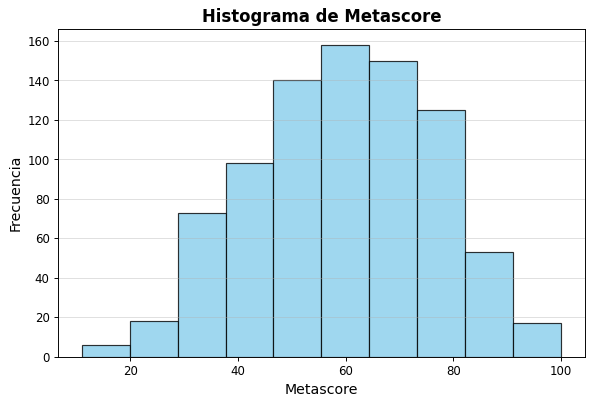

In [15]:
# Crear histograma de Metascore con 10 cubetas
plt.figure(figsize=(8, 5))
plt.hist(df['Metascore'], bins=10, edgecolor='black', color='skyblue', alpha=0.8)
plt.title('Histograma de Metascore', fontsize=14, fontweight='bold')
plt.xlabel('Metascore', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.grid(axis='y', alpha=0.4)
plt.show()


### 16. Crea un histograma de la variable Rating. Utiliza 10 cubetas

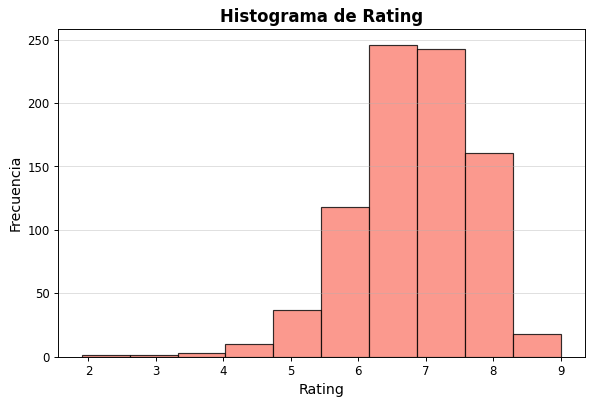

In [16]:
# Crear histograma de Rating con 10 cubetas
plt.figure(figsize=(8, 5))
plt.hist(df['Rating'], bins=10, edgecolor='black', color='salmon', alpha=0.8)
plt.title('Histograma de Rating', fontsize=14, fontweight='bold')
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.grid(axis='y', alpha=0.4)
plt.show()


### 17. Vuelve a describir el dataframe y observa la media de la variable `Ratings`

In [17]:
# Vuelve a describir el dataframe centrándose en la columna Rating
print(df['Rating'].describe())
print(f"\nLa media exacta de Rating es: {df['Rating'].mean():.4f}")


count    838.000000
mean       6.814320
std        0.877754
min        1.900000
25%        6.300000
50%        6.900000
75%        7.500000
max        9.000000
Name: Rating, dtype: float64

La media exacta de Rating es: 6.8143


### 18. Calcula este promedio con Numpy y después con un método de Pandas

In [18]:
# Calcular promedio de Rating con Numpy y con Pandas
promedio_np = np.mean(df['Rating'])
promedio_pd = df['Rating'].mean()

print(f"Promedio con Numpy: {promedio_np}")
print(f"Promedio con Pandas: {promedio_pd}")


Promedio con Numpy: 6.814319809069212
Promedio con Pandas: 6.814319809069212


### 19. Obten los valores únicos de la variable Rating y después ordénalos de menor a mayor

In [19]:
# Obtener valores únicos de la columna Rating y ordenarlos
ratings_unicos = df['Rating'].unique()
ratings_ordenados = np.sort(ratings_unicos)
print("Ratings únicos ordenados de menor a mayor:")
print(ratings_ordenados)


Ratings únicos ordenados de menor a mayor:
[1.9 2.7 3.9 4.  4.1 4.3 4.4 4.6 4.7 4.8 4.9 5.  5.1 5.2 5.3 5.4 5.5 5.6
 5.7 5.8 5.9 6.  6.1 6.2 6.3 6.4 6.5 6.6 6.7 6.8 6.9 7.  7.1 7.2 7.3 7.4
 7.5 7.6 7.7 7.8 7.9 8.  8.1 8.2 8.3 8.4 8.5 8.6 8.8 9. ]


### 20. Observa los ratings que te interesen y ahora filtra el dataframe con ese rating para ver cuáles son las películas con dicho rating

In [20]:
# Filtrar por una calificación alta de interés, por ejemplo 8.8
rating_interes = 8.8
peliculas_rating_alto = df[df['Rating'] == rating_interes]
print(f"Películas con Rating = {rating_interes}:")
display(peliculas_rating_alto[['Title', 'Director', 'Year', 'Rating', 'Revenue_Millions']])


Películas con Rating = 8.8:


,Title,Director,Year,Rating,Revenue_Millions
80,Inception,Christopher Nolan,2010,8.8,292.57


### 21. Obten los valores únicos de la variable Rating y la frecuencia total de cada uno de estos valores. Posteriormente crea un nuevo dataframe con essos valores

In [21]:
# Conteo de frecuencia de cada Rating y creación de nuevo dataframe
df_frecuencias = df['Rating'].value_counts().reset_index()
df_frecuencias.columns = ['rating', 'frecuencia']
print("Dataframe de frecuencias por Rating:")
display(df_frecuencias.head())


Dataframe de frecuencias por Rating:


,rating,frecuencia
0,7.0,43
1,6.7,42
2,7.1,40
3,7.8,38
4,7.2,38


### 22. Ordena el nuevo dataframe por la variable `rating`

In [22]:
# Ordenar el nuevo dataframe por la variable rating
df_frecuencias = df_frecuencias.sort_values(by='rating').reset_index(drop=True)
print("Frecuencias ordenadas de menor a mayor según el Rating:")
display(df_frecuencias.head())


Frecuencias ordenadas de menor a mayor según el Rating:


,rating,frecuencia
0,1.9,1
1,2.7,1
2,3.9,2
3,4.0,1
4,4.1,1


### 23. Crea una gráfica de barras con este nuevo dataframe ordenado

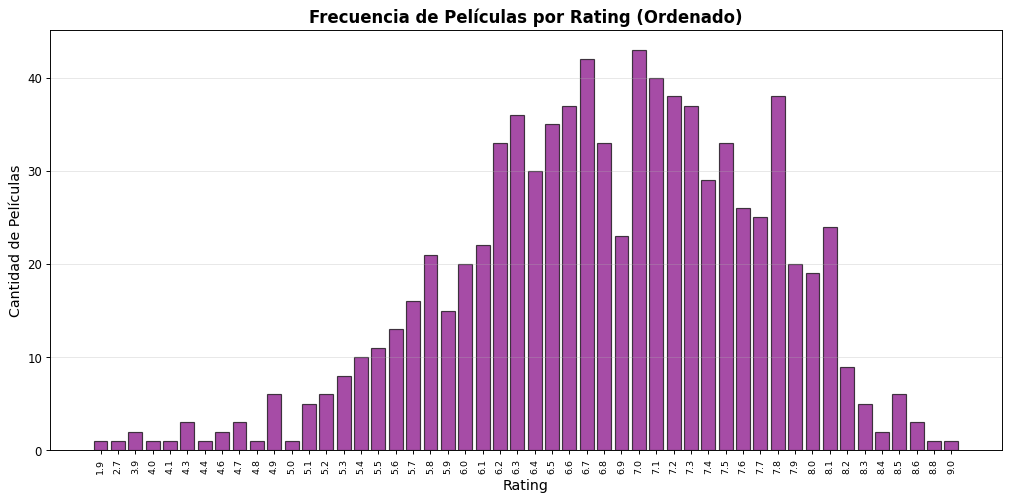

In [23]:
# Crear una gráfica de barras a partir del dataframe ordenado de frecuencias
plt.figure(figsize=(12, 6))
plt.bar(df_frecuencias['rating'].astype(str), df_frecuencias['frecuencia'], color='purple', edgecolor='black', alpha=0.7)
plt.title('Frecuencia de Películas por Rating (Ordenado)', fontsize=14, fontweight='bold')
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Cantidad de Películas', fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### 24. Crea la matriz de correlación del dataframe de películas

In [24]:
# Crear la matriz de correlación (sobre variables numéricas)
matriz_corr = df.select_dtypes(include=[np.number]).corr()
print("Matriz de Correlación de variables numéricas:")
display(matriz_corr)


Matriz de Correlación de variables numéricas:


,Rank,Year,Runtime_Minutes,Rating,Votes,Revenue_Millions,Metascore
Rank,1.000000,-0.312809,-0.254783,-0.243125,-0.303284,-0.273170,-0.195909
Year,-0.312809,1.000000,-0.101933,-0.145703,-0.362445,-0.129198,-0.062303
Runtime_Minutes,-0.254783,-0.101933,1.000000,0.374566,0.399298,0.281721,0.221397
Rating,-0.243125,-0.145703,0.374566,1.000000,0.517452,0.217106,0.672731
Votes,-0.303284,-0.362445,0.399298,0.517452,1.000000,0.636833,0.332674
Revenue_Millions,-0.273170,-0.129198,0.281721,0.217106,0.636833,1.000000,0.142397
Metascore,-0.195909,-0.062303,0.221397,0.672731,0.332674,0.142397,1.000000


### 25. Grafica la matriz de correlación utilizando `matshow()`

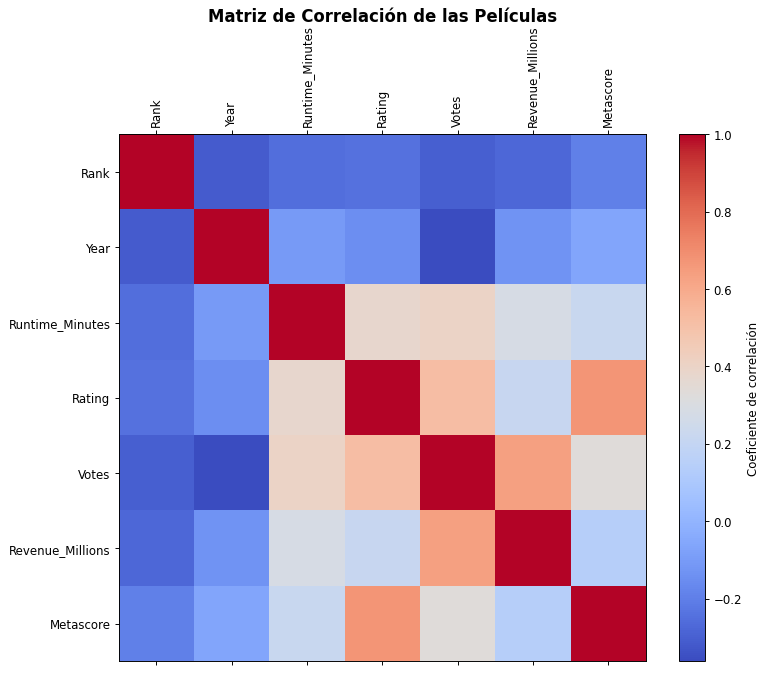

In [25]:
# Graficar la matriz de correlación utilizando matshow()
plt.figure(figsize=(10, 8))
plt.matshow(matriz_corr, cmap='coolwarm', fignum=1)
plt.colorbar(label='Coeficiente de correlación')

# Configurar los nombres en los ejes
columnas = matriz_corr.columns.tolist()
plt.xticks(range(len(columnas)), columnas, rotation=90, fontsize=10)
plt.yticks(range(len(columnas)), columnas, fontsize=10)

plt.title('Matriz de Correlación de las Películas', y=1.2, fontsize=14, fontweight='bold')
plt.show()


In [26]:
assert df.shape == (838,12)
assert df.isna().sum().sum() == 0
assert np.isclose(promedio_np,promedio_pd)
assert df_frecuencias.frecuencia.sum() == len(df)
print('Verificado: 838 películas completas; media Rating', promedio_pd)

Verificado: 838 películas completas; media Rating 6.814319809069212
